In [18]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core

from optim_utils import set_params
from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, jones_2009_model
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'


In [19]:

scale_factor = 1000

net = new_calcium_model()

location = 'proximal'
burst_std = 20
weights_ampa_p = {'L2_pyramidal': 5.4e-5, 'L5_pyramidal': 5.4e-5}
syn_delays_p = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=284)

# simulate the dipole, but do not automatically scale or smooth the result
dpl = simulate_dipole(net, tstop=310., n_trials=1, bsl_cor='calcium')[0]

trial_idx = 0  # single trial simulated, choose the first index
# to emulate a larger patch of cortex, we can apply a simple scaling factor
dpl.scale(scale_factor)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93569/112437963.py:20: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


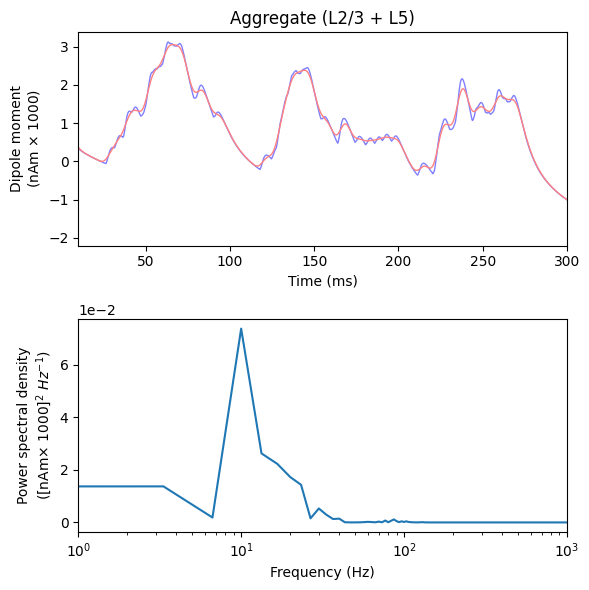

In [20]:
import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd

fig, axes = plt.subplots(2, 1, constrained_layout=True, figsize=(6, 6))
tmin, tmax = 10, 300  # exclude the initial burn-in period from the plots

# We'll make a copy of the dipole before smoothing in order to compare
window_len = 10  # convolve with a 10 ms-long Hamming window
dpl_smooth = dpl.copy().smooth(window_len)

# Overlay the traces for comparison. The function plot_dipole can plot a list
# of dipoles at once
dpl.plot(tmin=tmin, tmax=tmax, color='b', ax=axes[0], show=False)
dpl_smooth.plot(tmin=tmin, tmax=tmax, color='r', ax=axes[0], show=False)
axes[0].set_xlim((tmin, tmax))

plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[1], show=False)
axes[1].set_xscale('log')

plt.tight_layout()

In [21]:
location = 'distal'
burst_std = 15
weights_ampa_d = {'L2_pyramidal': 5.4e-5, 'L5_pyramidal': 5.4e-5}
syn_delays_d = {'L2_pyramidal': 5., 'L5_pyramidal': 5.}
net.add_bursty_drive(
    'alpha_dist', tstart=50.+7., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=296)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93569/3586640951.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


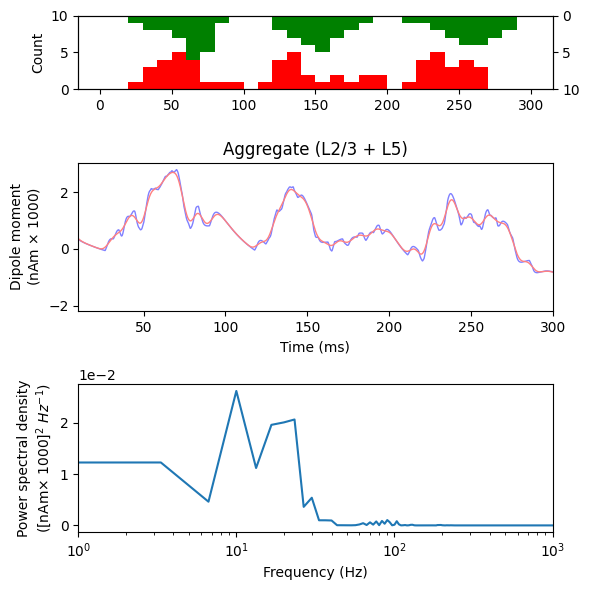

In [22]:
import numpy as np
dpl = simulate_dipole(net, tstop=310., n_trials=1, bsl_cor='calcium')[0]
dpl.scale(scale_factor)
fig, axes = plt.subplots(3, 1, constrained_layout=True, figsize=(6, 6), height_ratios=[0.5, 1, 1])
tmin, tmax = 10, 300  # exclude the initial burn-in period from the plots

bins = np.arange(0, 310, 10)  # histogram bins
# We'll make a copy of the dipole before smoothing in order to compare
window_len = 10  # convolve with a 10 ms-long Hamming window
dpl_smooth = dpl.copy().smooth(window_len)

# proximal and distal histogram
spike_prox = np.array(net.cell_response.spike_times_by_type['alpha_prox']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['alpha_dist']).reshape(-1,1)

axes[0].hist(spike_prox, bins, color='r')
axes[0].set_ylim([0, 10])
axes[0].set_ylabel('Count')
ax1tw = axes[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 10])
ax1tw.invert_yaxis()

# Overlay the traces for comparison. The function plot_dipole can plot a list
# of dipoles at once
dpl.plot(tmin=tmin, tmax=tmax, color='b', ax=axes[1], show=False)
dpl_smooth.plot(tmin=tmin, tmax=tmax, color='r', ax=axes[1], show=False)
axes[1].set_xlim((tmin, tmax))

plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[2], show=False)
axes[2].set_xscale('log')

plt.tight_layout()

fig.savefig(os.path.join(pathfig, 'alpha_beta_complex.png'))